# Example: Household consumption forecasting with the v2 data models

This notebook trains a forecasting model and forecasts with it through the [U2Demo data models v2](../README.md#data-model-versions) payloads, on the UCI Individual Household Electric Power Consumption dataset available [here](https://archive.ics.uci.edu/dataset/235/individual+household+electric+power+consumption).

The forecast is a `ForecastPayloadDM`: the consumption of the household's load as average power in kW, the series the optimisation engines read from the `hasForecastedProfile` of a load asset. [household_consumption.ipynb](household_consumption.ipynb) is the same example with the v1 data models.

## Imports

In [1]:
import json
from datetime import UTC, datetime

import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Code
from ucimlrepo import fetch_ucirepo

from u2demo_time_series_forecasting import ForecastInputV2, ForecastTrainingInputV2, predict_v2, train_v2
from u2demo_time_series_forecasting.constants.paths import LEADERBOARD_FILENAME, MODEL_DIR

## Data loading and preprocessing

- Loading the data from the UCI dataset
- Filling missing values
- Resampling to hourly average power

The v2 load forecasts are `ActivePower`: the average power over each timestep, in kW. `Global_active_power` is the average power of each minute in kW, so the value of an hour is the mean of its minutes.

In [2]:
individual_household_electric_power_consumption = fetch_ucirepo(id=235)

df_raw = individual_household_electric_power_consumption.data.features

df_raw.head()

.../site-packages/ucimlrepo/fetch.py:97: DtypeWarning: Columns (2,3,4,5,6,7) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv(data_url)


,Date,Time,Global_active_power,Global_reactive_power,Voltage,Global_intensity,Sub_metering_1,Sub_metering_2,Sub_metering_3
0,16/12/2006,17:24:00,4.216,0.418,234.840,18.400,0.000,1.000,17.0
1,16/12/2006,17:25:00,5.360,0.436,233.630,23.000,0.000,1.000,16.0
2,16/12/2006,17:26:00,5.374,0.498,233.290,23.000,0.000,2.000,17.0
3,16/12/2006,17:27:00,5.388,0.502,233.740,23.000,0.000,1.000,17.0
4,16/12/2006,17:28:00,3.666,0.528,235.680,15.800,0.000,1.000,17.0


In [3]:
# Convert "?" to NaN and ensure numeric type for "Global_active_power"
df_raw["Global_active_power"] = df_raw["Global_active_power"].replace("?", np.nan).astype(float)

# Create a "time" column by combining "Date" and "Time"
df_raw["time"] = df_raw["Date"] + " " + df_raw["Time"]
df_raw["time"] = pd.to_datetime(df_raw["time"], format="%d/%m/%Y %H:%M:%S")

# Average power of each minute, in kW
df_raw["value"] = df_raw["Global_active_power"]

df = df_raw[["time", "value"]].copy()

In [4]:
def fill_gaps(
    df: pd.DataFrame,
    value_col: str = "value",
    freq: str = "1min",
    short_gap: int = 15,  # minutes
    medium_gap: int = 180,  # minutes (3 hours)
    seasonal_lag: int = 1440,  # 1 day for minutely data
) -> pd.DataFrame:
    """
    Fill missing values in a minutely time series based on gap size.

    Parameters
    ----------
    df : pd.DataFrame
        Must have a DatetimeIndex and a value column.
    value_col : str
        Column name for the time series.
    freq : str
        Expected frequency (default: '1min').
    short_gap : int
        Max size (in minutes) for linear interpolation.
    medium_gap : int
        Max size (in minutes) for time-of-day imputation.
    seasonal_lag : int
        Lag for seasonal fill (default: 1440 minutes = 1 day).

    Returns
    -------
    pd.DataFrame
        DataFrame with filled values, rounded to 3 decimals like the raw readings.

    """
    df = df.copy()

    # Reindex to the expected frequency, so that missing minutes become NaN
    df = df.asfreq(freq)

    values = df[value_col]

    # --- Identify gaps ---
    is_na = values.isna()
    gap_id = (is_na != is_na.shift()).cumsum()
    gap_sizes = is_na.groupby(gap_id).transform("sum")

    # --- 1. Short gaps → linear interpolation ---
    short_mask = is_na & (gap_sizes <= short_gap)
    df.loc[short_mask, value_col] = values.interpolate(method="time")

    # --- 2. Medium gaps → time-of-day mean ---
    medium_mask = is_na & (gap_sizes > short_gap) & (gap_sizes <= medium_gap)

    if medium_mask.any():
        # Compute time-of-day averages (excluding NaNs)
        time_means = df.groupby(df.index.time)[value_col].transform("mean")
        df.loc[medium_mask, value_col] = time_means[medium_mask]

    # --- 3. Long gaps → seasonal (previous day) ---
    long_mask = is_na & (gap_sizes > medium_gap)

    if long_mask.any():
        seasonal_values = df[value_col].shift(seasonal_lag)
        df.loc[long_mask, value_col] = seasonal_values[long_mask]

    # --- 4. Final fallback (in case seasonal also missing) ---
    df[value_col] = df[value_col].ffill().bfill()

    df[value_col] = df[value_col].round(3)

    return df

In [5]:
df = df.set_index("time").pipe(fill_gaps, value_col="value").reset_index()

In [6]:
# Resample to the hourly average power (kW)
df = df.set_index("time").resample("h").mean().reset_index()

df.head()

,time,value
0,2006-12-16 17:00:00,4.222889
1,2006-12-16 18:00:00,3.632200
2,2006-12-16 19:00:00,3.400233
3,2006-12-16 20:00:00,3.268567
4,2006-12-16 21:00:00,3.056467


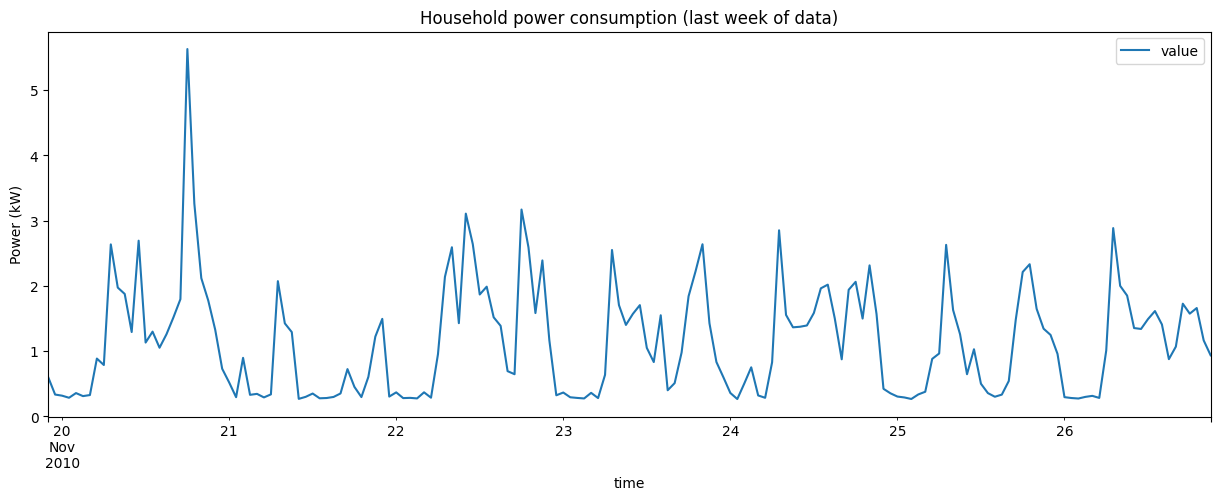

In [7]:
df.iloc[-24 * 7 :].plot(
    x="time",
    y="value",
    ylabel="Power (kW)",
    figsize=(15, 5),
    title="Household power consumption (last week of data)",
)

plt.show()

## Training a model on historical data

The training request uses the v2 vocabulary: `hasTimeParameters`, `hasUserForecastPreferences` (with the `pinball` loss function, the weighted quantile loss) and a target series that names its quantity (`observedProperty`), its subject (`hasFeatureOfInterest`, the household's load asset) and its unit.

The timestamps of the dataset have no time zone: the library reads them as UTC.

In [8]:
training_values = df.rename(columns={"time": "timestamp"}).to_dict(orient="records")

training_payload = {
    "hasTimeParameters": {
        "timestep_minutes": 60,
        "horizon_hours": 24,
        "scheduling_time": datetime.now(UTC).isoformat(),
    },
    "hasUserForecastPreferences": {
        "forecast_type": "STOCHASTIC",
        "model_id": "uci-household-load",
        "model_version": "1.0.0",
        "model_preset": "fast_training",  # use "fast_training" or "chronos2" for CPU, switch to "medium_quality" or "best_quality" for better performance with GPU
        "lookback_steps": 2048,
        "loss_function": "pinball",
        "quantile_levels": [0.1, 0.5, 0.9],
    },
    "target_series": {
        "series_id": "house_1_consumption",
        "observedProperty": "ActivePower",
        "hasFeatureOfInterest": "load_house_1",
        "asset_type": "Load",
        "unit_symbol": "kW",
        "unit": "unit:KiloW",
        "training_values": training_values,
    },
    # You can optionally add exogenous variables
    # "location": {
    #     "latitude": 48.778611,
    #     "longitude": 2.290556,
    # },
    # "features": ["weather", "temporal"],
}

training_input = ForecastTrainingInputV2.model_validate(training_payload)

In [9]:
train_v2(training_input)

Beginning AutoGluon training...
AutoGluon will save models to 'models/uci-household-load_1.0.0'
=================== System Info ===================
AutoGluon Version:  1.5.0
Python Version:     3.12.3
Operating System:   Linux
Platform Machine:   x86_64
Platform Version:   #1 SMP PREEMPT_DYNAMIC Thu Jun 18 21:54:43 UTC 2026
CPU Count:          28
Pytorch Version:    2.9.1+cpu
CUDA Version:       CUDA is not available
GPU Memory:         
Total GPU Memory:   Free: 0.00 GB, Allocated: 0.00 GB, Total: 0.00 GB
GPU Count:          0
Memory Avail:       6.99 GB / 15.46 GB (45.2%)
Disk Space Avail:   577.46 GB / 1006.85 GB (57.4%)
Setting presets to: fast_training

Fitting with arguments:
{'enable_ensemble': True,
 'eval_metric': WQL,
 'freq': 'h',
 'hyperparameters': 'very_light',
 'known_covariates_names': [],
 'num_val_windows': 1,
 'prediction_length': 24,
 'quantile_levels': [0.1, 0.5, 0.9],
 'random_seed': 123,
 'refit_full': False,
 'skip_model_selection': False,
 'target': 'value',
 '

## Displaying models' performance

The score columns correspond to the metric of the `pinball` loss function, the Weighted Quantile Loss (WQL). In addition the Weighted Absolute Percentage Error (WAPE) is computed.

Note: All metrics signs have been flipped to keep a logic of "higher is better" for all metrics

In [10]:
eval_df = pd.read_csv(MODEL_DIR / "uci-household-load_1.0.0" / LEADERBOARD_FILENAME, index_col=False)
eval_df

,model,score_test,score_val,pred_time_test,pred_time_val,fit_time_marginal,fit_order,WAPE
0,DirectTabular,-0.148834,-0.227846,0.191756,0.175426,3.121774,4.0,-0.201468
1,WeightedEnsemble,-0.151254,-0.225155,1.308338,1.320807,0.291663,7.0,-0.204666
2,ETS,-0.216088,-2.002505,4.719525,2.495276,0.025320,5.0,-0.308806
3,SeasonalNaive,-0.262770,-0.356034,1.115548,1.144372,0.023284,2.0,-0.405338
4,Theta,-0.351325,-0.324809,1.745466,1.947828,0.023474,6.0,-0.362796
5,RecursiveTabular,-0.371199,-0.438320,0.132822,0.097632,1.311352,3.0,-0.247351
6,Naive,-0.455337,-0.442160,1.103892,1.371919,0.030373,1.0,-0.451299


## Forecasting on unseen data

In [11]:
# Hold out the last 24 hours of data and keep the 2048 hours before them as lookback data for the model
df_forecast = df.iloc[-2048 - 24 : -24]

In [12]:
historical_values = df_forecast.rename(columns={"time": "timestamp"}).to_dict(orient="records")

forecast_payload = {
    "forecast_type": "STOCHASTIC",
    "hasTimeParameters": {
        "timestep_minutes": 60,
        "horizon_hours": 24,
        "scheduling_time": datetime.now(UTC).isoformat(),
    },
    "model_id": "uci-household-load",
    "model_version": "1.0.0",
    "target_series": {
        "series_id": "house_1_consumption",
        "observedProperty": "ActivePower",
        "hasFeatureOfInterest": "load_house_1",
        "asset_type": "Load",
        "unit_symbol": "kW",
        "unit": "unit:KiloW",
        "historical_values": historical_values,
    },
}

forecast_input = ForecastInputV2.model_validate(forecast_payload)

In [13]:
forecast = predict_v2(forecast_input)

2026-11-20 15:00:18,992 - u2demo - INFO - Loading predictor from models/uci-household-load_1.0.0
Loading predictor from path models/uci-household-load_1.0.0
2026-11-20 15:00:19,022 - u2demo - INFO - Predictor loaded and persisted
Model not specified in predict, will default to the model with the best validation score: WeightedEnsemble


## The forecast payload

`forecast` is a `ForecastV2`, a `ForecastPayloadDM` that can be passed as the `hasForecastedProfile` of the household's load asset; `forecast.model_dump_json()` gives the JSON payload. Its first two values:

In [14]:
payload = forecast.model_dump(mode="json")
series = payload["hasForecastSeries"][0]
series["hasValues"] = series["hasValues"][:2]

Code(json.dumps(payload, indent=2), language="json")

{
  "forecastId": "dc485adf-5e09-473a-8c97-03491cddc1a3",
  "forecast_date": "2026-11-20T14:00:20.259539Z",
  "forecast_type": "STOCHASTIC",
  "hasForecastSeries": [
    {
      "series_id": "house_1_consumption",
      "observedProperty": "ActivePower",
      "hasFeatureOfInterest": "load_house_1",
      "unit_symbol": "kW",
      "unit": "unit:KiloW",
      "model_id": "uci-household-load_1.0.0",
      "hasValues": [
        {
          "timestamp": "2010-11-25T22:00:00Z",
          "hasResult": {
            "numericValue": 1.0255559002304078,
            "unit": "unit:KiloW"
          },
          "quantiles": {
            "0.1": 0.49458443456352247,
            "0.5": 1.0255559002304078,
            "0.9": 2.10918955967247
          }
        },
        {
          "timestamp": "2010-11-25T23:00:00Z",
          "hasResult": {
            "numericValue": 0.5487310090446472,
            "unit": "unit:KiloW"
          },
          "quantiles": {
            "0.1": 0.26787559362113966,
            "0.5": 0.5487310090446472,
            "0.9": 1.6431190749388884
          }
        }
      ]
    }
  ]
}

## Visualizing forecasts

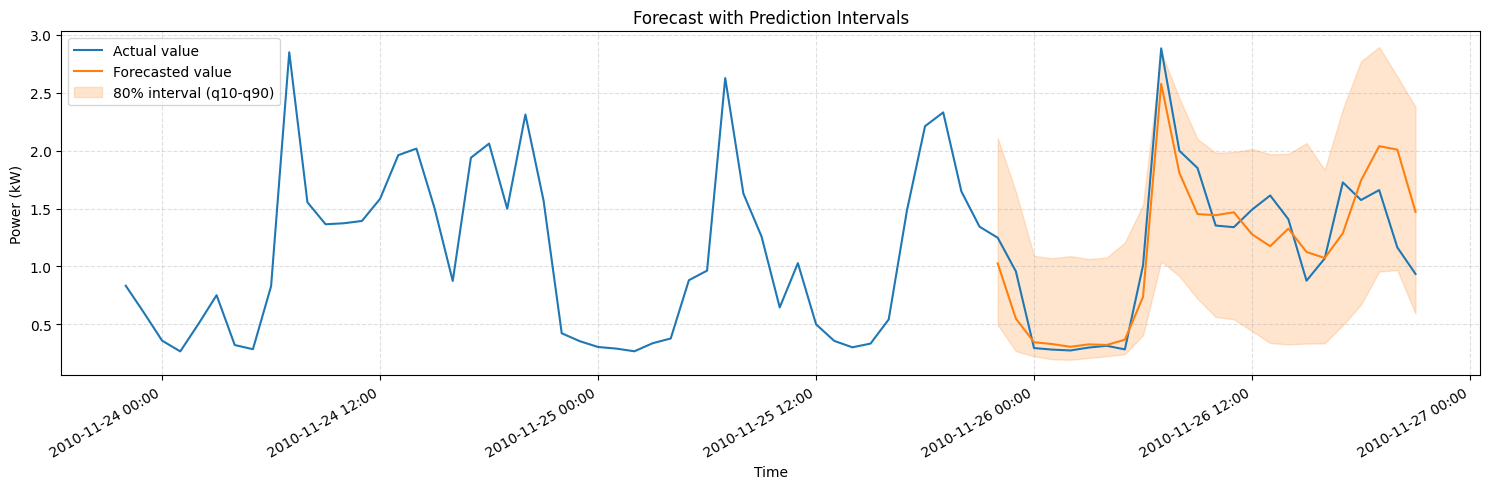

In [15]:
forecasted_values = forecast.hasForecastSeries[0].hasValues

# The forecast timestamps are in UTC, the time zone the dataset's timestamps were read in
times = [v.timestamp.replace(tzinfo=None) for v in forecasted_values]
values = [v.hasResult.numericValue for v in forecasted_values]
q10 = [v.quantiles["0.1"] for v in forecasted_values]
q90 = [v.quantiles["0.9"] for v in forecasted_values]

fig, ax = plt.subplots(figsize=(15, 5))

# Actual value
ax.plot(
    df.iloc[-24 * 3 :]["time"],
    df.iloc[-24 * 3 :]["value"],
    color="tab:blue",
    label="Actual value",
)

# Forecasted value
ax.plot(times, values, color="tab:orange", label="Forecasted value")

# 80 % prediction interval (q10 - q90)
ax.fill_between(times, q10, q90, alpha=0.20, color="tab:orange", label="80% interval (q10-q90)")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m-%d %H:%M"))
fig.autofmt_xdate(rotation=30)

ax.set_title("Forecast with Prediction Intervals")
ax.set_xlabel("Time")
ax.set_ylabel("Power (kW)")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)

plt.tight_layout()